In [1]:
!pip install praat-parselmouth librosa soundfile scikit-learn xgboost catboost torch optuna tqdm seaborn scipy pandas numpy matplotlib psutil

In [2]:
# importing relevant libraries
import os
import re
import glob
import time
import json
import copy
import random
import hashlib
import warnings
from collections import OrderedDict

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import parselmouth
from parselmouth.praat import call
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from tqdm.auto import tqdm
from scipy import stats
from scipy.signal import fftconvolve
from scipy.spatial.distance import pdist
from IPython.display import Audio, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import optuna

try:
    import psutil
except ImportError:
    psutil = None

warnings.filterwarnings("ignore")

# Loading the dataset 
ROOT = r"C:\Users\user\Desktop\Voice_Dataset"
OUT_DIR = os.path.join(ROOT, "outputs")
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
FIG_DIR = os.path.join(OUT_DIR, "figures")
for d in [OUT_DIR, CKPT_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

NAVY = "#0b1026"
PANEL = "#141a3b"
TEXT = "#e8e8f5"
GRID = "#2a3166"
LABEL_COLORS = {"Healthy": mcolors.to_hex(plt.cm.plasma(0.80)),
                "Parkinsons": mcolors.to_hex(plt.cm.plasma(0.22))}

sns.set_theme(style="dark")
plt.rcParams.update({
    "figure.facecolor": NAVY, "axes.facecolor": PANEL, "savefig.facecolor": NAVY,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "text.color": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT, "axes.titlecolor": TEXT,
    "grid.color": GRID, "axes.grid": True, "grid.alpha": 0.5,
    "legend.facecolor": PANEL, "legend.edgecolor": GRID, "legend.labelcolor": TEXT,
    "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110, "savefig.dpi": 300,
})

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=300, bbox_inches="tight")

def make_grid(n, ncols=4, size=3.6):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

Device: cpu


In [3]:
# file inventory
EXPECTED = {"Healthy": ("healthy", 574), "Parkinsons": ("parkinsons", 560)}

rows = []
for folder, (prefix, n_expected) in EXPECTED.items():
    fdir = os.path.join(ROOT, folder)
    for f in sorted(os.listdir(fdir)):
        if not f.lower().endswith(".wav"):
            continue
        stem = os.path.splitext(f)[0]
        m = re.match(rf"^{prefix}_(\d+)$", stem, flags=re.IGNORECASE)
        rows.append(dict(recording_id=stem, label=folder, path=os.path.join(fdir, f),
                         index=int(m.group(1)) if m else -1, name_ok=bool(m)))
inv = pd.DataFrame(rows)

print(inv.groupby("label").size())
print("Files not matching the expected naming pattern:", int((~inv.name_ok).sum()))
for folder, (prefix, n_expected) in EXPECTED.items():
    present = set(inv.loc[(inv.label == folder) & inv.name_ok, "index"])
    missing = sorted(set(range(n_expected)) - present)
    extra = sorted(present - set(range(n_expected)))
    print(folder, "| expected", n_expected, "| found", len(present),
          "| missing indices:", missing, "| unexpected indices:", extra)
print("Filenames contain only a label and a running number, so no speaker identifier is available.")
inv.head()

label
Healthy       574
Parkinsons    560
dtype: int64
Files not matching the expected naming pattern: 0
Healthy | expected 574 | found 574 | missing indices: [] | unexpected indices: []
Parkinsons | expected 560 | found 560 | missing indices: [] | unexpected indices: []
Filenames contain only a label and a running number, so no speaker identifier is available.


,recording_id,label,path,index,name_ok
0,healthy_000,Healthy,C:\Users\user\Desktop\Voice_Dataset\Healthy\he...,0,True
1,healthy_001,Healthy,C:\Users\user\Desktop\Voice_Dataset\Healthy\he...,1,True
2,healthy_002,Healthy,C:\Users\user\Desktop\Voice_Dataset\Healthy\he...,2,True
3,healthy_003,Healthy,C:\Users\user\Desktop\Voice_Dataset\Healthy\he...,3,True
4,healthy_004,Healthy,C:\Users\user\Desktop\Voice_Dataset\Healthy\he...,4,True


In [4]:
# Audio inspection (sampling rate, channels, duration, clipping, silence, duplicates)
def inspect_file(path):
    info = sf.info(path)
    y, sr = sf.read(path, always_2d=True, dtype="float64")
    mono = y.mean(axis=1)
    n = len(mono)
    rec = dict(sr=sr, channels=info.channels, subtype=info.subtype, n_samples=n,
               duration=n / sr, peak=float(np.max(np.abs(y))),
               rms=float(np.sqrt(np.mean(mono ** 2))), dc_offset=float(np.mean(mono)),
               clip_frac=float(np.mean(np.abs(y) >= 0.999)),
               md5=hashlib.md5(y.tobytes()).hexdigest())
    mono32 = mono.astype(np.float32)
    iv = librosa.effects.split(mono32, top_db=40)
    nonsil = int(sum(e - s for s, e in iv)) if len(iv) else 0
    rec["nonsilent_sec"] = nonsil / sr
    rec["nonsilent_frac"] = nonsil / n
    rms = librosa.feature.rms(y=mono32)[0]
    rec["dyn_range_db"] = float(20 * np.log10((np.percentile(rms, 95) + 1e-9) / (np.percentile(rms, 5) + 1e-9)))
    return rec

records = []
for r in tqdm(inv.itertuples(), total=len(inv)):
    try:
        rec = inspect_file(r.path)
        rec.update(recording_id=r.recording_id, label=r.label, path=r.path, index=r.index)
    except Exception as e:
        rec = dict(recording_id=r.recording_id, label=r.label, path=r.path, index=r.index, error=str(e))
    records.append(rec)

insp = pd.DataFrame(records)
if "error" in insp.columns:
    print("Files that failed to load:")
    print(insp.loc[insp.error.notna(), ["recording_id", "error"]])
    insp = insp[insp.error.isna()].drop(columns="error").reset_index(drop=True)
insp.to_csv(os.path.join(OUT_DIR, "audio_inspection.csv"), index=False)
print("Inspected recordings:", len(insp))

  0%|          | 0/1134 [00:00<?, ?it/s]

Inspected recordings: 1134


label                Healthy  Parkinsons
duration      count  574.000     560.000
              mean     3.025       3.543
              std      1.053       1.494
              min      1.478       1.378
              25%      1.992       2.397
              50%      2.868       3.304
              75%      3.857       4.131
              max      5.764       7.208
nonsilent_sec count  574.000     560.000
              mean     3.025       3.543
              std      1.053       1.494
              min      1.478       1.378
              25%      1.992       2.397
              50%      2.868       3.304
              75%      3.857       4.131
              max      5.764       7.208
peak          count  574.000     560.000
              mean     0.994       0.992
              std      0.018       0.033
              min      0.848       0.715
              25%      1.000       1.000
              50%      1.000       1.000
              75%      1.000       1.000
              ma

,recording_id,label,md5
322,healthy_322,Healthy,004a988cd8d2a78f2a3835eafbbd8782
35,healthy_035,Healthy,004a988cd8d2a78f2a3835eafbbd8782
669,parkinsons_095,Parkinsons,009b5b554193007d5e9ca4efb2367bf8
949,parkinsons_375,Parkinsons,009b5b554193007d5e9ca4efb2367bf8
939,parkinsons_365,Parkinsons,00e6c477e2463ea412fb794d582e8e03
...,...,...,...
785,parkinsons_211,Parkinsons,fecddaa7f7b8e9010ea5ae40fe5f4d79
953,parkinsons_379,Parkinsons,ffb2ed88230447913bc7a026d27da5ca
673,parkinsons_099,Parkinsons,ffb2ed88230447913bc7a026d27da5ca
341,healthy_341,Healthy,fff4024eb40834884bb6b5e253f5e300


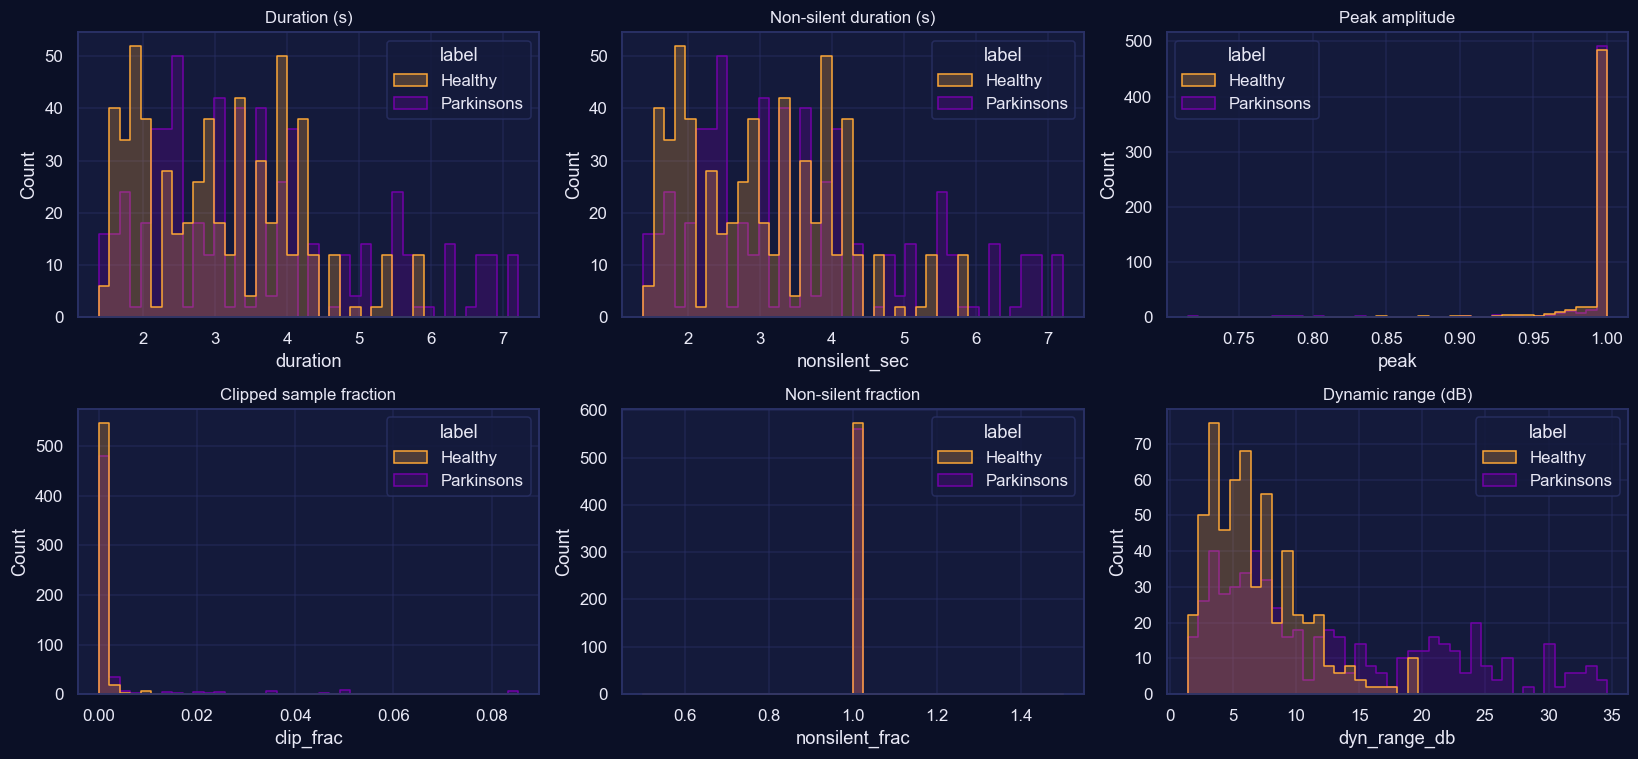

In [5]:
# Inspection summary and plots
pd.set_option("display.width", 200)
print(insp.groupby("label")[["duration", "nonsilent_sec", "peak", "clip_frac", "dyn_range_db"]].describe().T.round(3))
print()
print(insp.groupby(["label", "sr"]).size())
print(insp.groupby(["label", "channels"]).size())
print(insp.groupby(["label", "subtype"]).size())

dups = insp[insp.duplicated("md5", keep=False)].sort_values("md5")
print("\nRecordings that share byte-identical audio with another file:", len(dups))
if len(dups):
    display(dups[["recording_id", "label", "md5"]])

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, title) in zip(axes.ravel(), [("duration", "Duration (s)"), ("nonsilent_sec", "Non-silent duration (s)"),
                                          ("peak", "Peak amplitude"), ("clip_frac", "Clipped sample fraction"),
                                          ("nonsilent_frac", "Non-silent fraction"), ("dyn_range_db", "Dynamic range (dB)")]):
    sns.histplot(data=insp, x=col, hue="label", palette=LABEL_COLORS, element="step", bins=40, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Healthy healthy_514 | sr 8000 | duration 1.79 s


Healthy healthy_070 | sr 8000 | duration 3.18 s


Parkinsons parkinsons_453 | sr 8000 | duration 1.59 s


Parkinsons parkinsons_341 | sr 8000 | duration 2.22 s


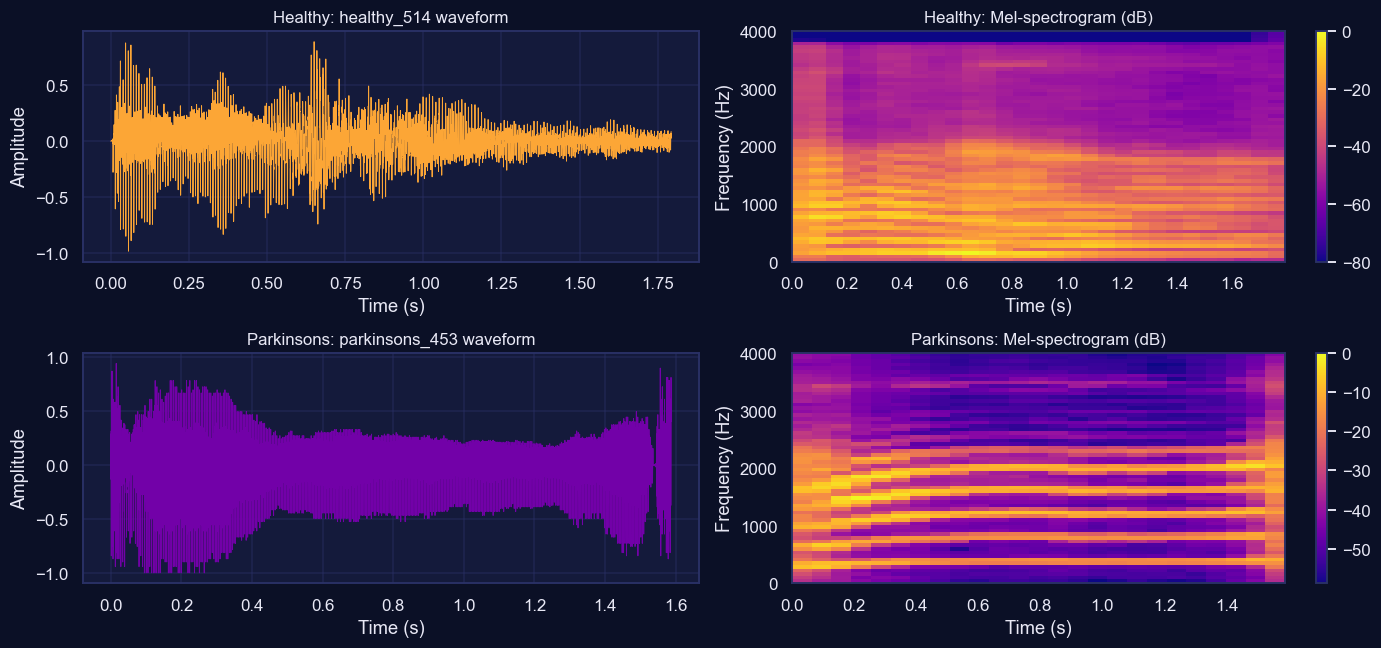

In [6]:
# listen to examples and view waveform and Mel-spectrogram
# Listen to a few files to decide whether they are sustained vowels or connected speech
for lab in ["Healthy", "Parkinsons"]:
    sub = insp[insp.label == lab].sample(2, random_state=SEED)
    for r in sub.itertuples():
        y, sr_ = sf.read(r.path, always_2d=True)
        y = y.mean(axis=1)
        print(lab, r.recording_id, "| sr", sr_, "| duration", round(r.duration, 2), "s")
        display(Audio(y, rate=sr_))

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for i, lab in enumerate(["Healthy", "Parkinsons"]):
    r = insp[insp.label == lab].sample(1, random_state=SEED).iloc[0]
    y, sr_ = sf.read(r.path, always_2d=True)
    y = y.mean(axis=1).astype(np.float32)
    t = np.arange(len(y)) / sr_
    axes[i, 0].plot(t, y, color=LABEL_COLORS[lab], lw=0.6)
    axes[i, 0].set_title(f"{lab}: {r.recording_id} waveform")
    axes[i, 0].set_xlabel("Time (s)")
    axes[i, 0].set_ylabel("Amplitude")
    M = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr_, n_mels=64), ref=np.max)
    im = axes[i, 1].imshow(M, origin="lower", aspect="auto", cmap="plasma", extent=[0, t[-1], 0, sr_ / 2])
    axes[i, 1].set_title(f"{lab}: Mel-spectrogram (dB)")
    axes[i, 1].set_xlabel("Time (s)")
    axes[i, 1].set_ylabel("Frequency (Hz)")
    axes[i, 1].grid(False)
    plt.colorbar(im, ax=axes[i, 1])
plt.tight_layout()
plt.show()

In [7]:
# preprocessing configuration and loader
SR = int(min(16000, insp["sr"].min()))
MAX_SEC = float(np.clip(np.round(insp["nonsilent_sec"].quantile(0.90), 1), 1.0, 5.0))
TRIM_DB = 35
MIN_SEC = 0.5
HOP = int(SR * 0.010)
N_FFT = 1024 if SR >= 16000 else 512
N_MELS = 64
FMAX = SR // 2
L_FIXED = int(MAX_SEC * SR)
T_FIXED = L_FIXED // HOP + 1
PAD_DB = -100.0
F0_MIN, F0_MAX = 75.0, 500.0
MIN_VOICED = 0.30
print(dict(SR=SR, MAX_SEC=MAX_SEC, HOP=HOP, N_FFT=N_FFT, L_FIXED=L_FIXED, T_FIXED=T_FIXED))

def peak_norm(y, level=0.95):
    return (y / (np.max(np.abs(y)) + 1e-9) * level).astype(np.float32)

def pad_to(a, length, value=0.0):
    pad = length - a.shape[-1]
    if pad <= 0:
        return a[..., :length]
    widths = [(0, 0)] * a.ndim
    widths[-1] = (0, pad)
    return np.pad(a, widths, constant_values=value)

def load_clean(path):
    y, native = sf.read(path, always_2d=True, dtype="float32")
    y = y.mean(axis=1)
    if native != SR:
        y = librosa.resample(y, orig_sr=native, target_sr=SR)
    y = y - np.mean(y)
    y, _ = librosa.effects.trim(y, top_db=TRIM_DB)
    if len(y) < 2 * HOP:
        return y.astype(np.float32)
    y = peak_norm(y)
    # If longer than the model window, keep the window with the highest energy
    if len(y) > L_FIXED:
        cs = np.concatenate([[0.0], np.cumsum(y.astype(np.float64) ** 2)])
        starts = np.arange(0, len(y) - L_FIXED + 1, int(0.25 * SR))
        energy = cs[starts + L_FIXED] - cs[starts]
        s = int(starts[np.argmax(energy)])
        y = y[s:s + L_FIXED]
    return y.astype(np.float32)

{'SR': 8000, 'MAX_SEC': 5.0, 'HOP': 80, 'N_FFT': 512, 'L_FIXED': 40000, 'T_FIXED': 501}


In [8]:
# reference target extraction (Praat via Parselmouth, Librosa) and engineered features
def praat_measures(y, sr):
    out = dict(f0_mean=np.nan, f0_median=np.nan, f0_std=np.nan, voiced_frac=0.0,
               jitter=np.nan, shimmer=np.nan, hnr=np.nan)
    snd = parselmouth.Sound(y.astype(np.float64), sampling_frequency=float(sr))
    try:
        pitch = snd.to_pitch(time_step=0.01, pitch_floor=F0_MIN, pitch_ceiling=F0_MAX)
        f0 = pitch.selected_array["frequency"]
        voiced = f0[f0 > 0]
        out["voiced_frac"] = float(len(voiced) / max(len(f0), 1))
        if len(voiced) >= 5:
            out["f0_mean"] = float(np.mean(voiced))
            out["f0_median"] = float(np.median(voiced))
            out["f0_std"] = float(np.std(voiced))
    except Exception:
        pass
    try:
        pp = call(snd, "To PointProcess (periodic, cc)", F0_MIN, F0_MAX)
        if call(pp, "Get number of points") >= 5:
            out["jitter"] = float(call(pp, "Get jitter (local)", 0, 0, 0.0001, 0.02, 1.3))
            out["shimmer"] = float(call([snd, pp], "Get shimmer (local)", 0, 0, 0.0001, 0.02, 1.3, 1.6))
    except Exception:
        pass
    try:
        harm = call(snd, "To Harmonicity (cc)", 0.01, F0_MIN, 0.1, 1.0)
        out["hnr"] = float(call(harm, "Get mean", 0, 0))
    except Exception:
        pass
    return out

def process_signal(y):
    # Returns recording-level scalars (targets, fingerprint, engineered features) and frame-level arrays
    y = np.asarray(y, dtype=np.float32)
    sc_ = praat_measures(y, SR)
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP, center=True)) ** 2
    amp = np.sqrt(S)
    cent = librosa.feature.spectral_centroid(S=amp, sr=SR, n_fft=N_FFT)[0]
    bw = librosa.feature.spectral_bandwidth(S=amp, sr=SR, n_fft=N_FFT)[0]
    P = S / (S.sum(axis=0, keepdims=True) + 1e-12)
    ent = -(P * np.log2(P + 1e-12)).sum(axis=0) / np.log2(S.shape[0])
    mel = librosa.feature.melspectrogram(S=S, sr=SR, n_mels=N_MELS, fmax=FMAX)
    logmel = librosa.power_to_db(mel, ref=1.0, amin=1e-10, top_db=None)
    mfcc20 = librosa.feature.mfcc(S=logmel, n_mfcc=20)

    # Targets: recording-level means over frames (F0 is the mean over voiced frames)
    sc_["spec_centroid"] = float(np.mean(cent))
    sc_["spec_bandwidth"] = float(np.mean(bw))
    sc_["spec_entropy"] = float(np.mean(ent))
    for i in range(1, 14):
        sc_[f"mfcc_{i}"] = float(np.mean(mfcc20[i]))
        sc_[f"fp_mfcc_std_{i}"] = float(np.std(mfcc20[i]))

    # Engineered features for the conventional baselines (Mel band statistics and general descriptors)
    for k in range(N_MELS):
        sc_[f"ft_melmean_{k}"] = float(logmel[k].mean())
        sc_[f"ft_melstd_{k}"] = float(logmel[k].std())
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)[0]
    rms_db = 20 * np.log10(rms + 1e-9)
    sc_["ft_zcr"] = float(np.mean(librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP)))
    sc_["ft_rms_mean"] = float(rms_db.mean())
    sc_["ft_rms_std"] = float(rms_db.std())
    sc_["ft_rolloff"] = float(np.mean(librosa.feature.spectral_rolloff(S=amp, sr=SR, n_fft=N_FFT)))
    sc_["ft_flatness"] = float(np.mean(librosa.feature.spectral_flatness(S=amp)))
    return dict(scalars=sc_, logmel=logmel.astype(np.float32), mfcc=mfcc20.astype(np.float32))

In [9]:
# building the structured regression dataset 
records, wave_list, mel_list, mfcc_list, nfr_list, failed = [], [], [], [], [], []

for r in tqdm(insp.itertuples(), total=len(insp)):
    try:
        y = load_clean(r.path)
        if len(y) < 2 * HOP:
            raise ValueError("signal too short after trimming")
        res = process_signal(y)
    except Exception as e:
        failed.append((r.recording_id, str(e)))
        continue
    rec = dict(recording_id=r.recording_id, label=r.label, index=r.index,
               n_samples=len(y), dur_used=len(y) / SR, native_sr=r.sr)
    rec.update(res["scalars"])
    records.append(rec)
    wave_list.append(pad_to(y, L_FIXED))
    mel_list.append(pad_to(res["logmel"], T_FIXED, PAD_DB))
    mfcc_list.append(pad_to(res["mfcc"], T_FIXED, 0.0))
    nfr_list.append(res["logmel"].shape[1])

data = pd.DataFrame(records)
WAVE_ALL = np.stack(wave_list).astype(np.float32)
MEL_ALL = np.stack(mel_list).astype(np.float32)
MFCC_ALL = np.stack(mfcc_list).astype(np.float32)
NFR_ALL = np.array(nfr_list)
del wave_list, mel_list, mfcc_list

data.to_csv(os.path.join(OUT_DIR, "reference_targets.csv"), index=False)
np.savez_compressed(os.path.join(OUT_DIR, "arrays.npz"), wave=WAVE_ALL, mel=MEL_ALL, mfcc=MFCC_ALL, nfr=NFR_ALL)
print("Processed:", len(data), "| failed:", len(failed))
for item in failed:
    print(item)
print(data.groupby("label").size())

  0%|          | 0/1134 [00:00<?, ?it/s]

Processed: 1134 | failed: 0
label
Healthy       574
Parkinsons    560
dtype: int64


In [10]:
# Quality control flags (flags only, nothing is imputed)
v = data["voiced_frac"] >= MIN_VOICED
data["qc_dur"] = data["dur_used"] >= MIN_SEC
data["qc_f0"] = (v & data["f0_mean"].between(F0_MIN * 1.1, F0_MAX * 0.9)
                 & ((data["f0_std"] / data["f0_mean"]) < 0.5))
data["qc_jitter"] = v & data["jitter"].between(1e-6, 0.20)
data["qc_shimmer"] = v & data["shimmer"].between(1e-6, 0.50)
data["qc_hnr"] = v & data["hnr"].between(-10, 45)
spec_cols = ["spec_centroid", "spec_bandwidth", "spec_entropy"] + [f"mfcc_{i}" for i in range(1, 14)]
data["qc_spec"] = np.isfinite(data[spec_cols]).all(axis=1)

qc_cols = ["qc_dur", "qc_f0", "qc_jitter", "qc_shimmer", "qc_hnr", "qc_spec"]
print("Pass rate per QC rule and label:")
print(data.groupby("label")[qc_cols].mean().round(3))
print("\nMissing raw measurements per label:")
print(data.groupby("label")[["f0_mean", "jitter", "shimmer", "hnr"]].agg(lambda s: int(s.isna().sum())))
print("\nMedian voiced fraction per label:")
print(data.groupby("label")["voiced_frac"].median().round(3))

# Extreme outliers (3 x IQR) are reported but not removed
for c in ["f0_mean", "jitter", "shimmer", "hnr", "spec_centroid"]:
    s = data[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    n_out = int(((s < q1 - 3 * (q3 - q1)) | (s > q3 + 3 * (q3 - q1))).sum())
    print(f"{c}: {n_out} extreme outliers flagged, kept")
print("\nIf jitter or shimmer pass rates are low, remove those groups from USE_GROUPS in the next cell.")

Pass rate per QC rule and label:
            qc_dur  qc_f0  qc_jitter  qc_shimmer  qc_hnr  qc_spec
label                                                            
Healthy        1.0  0.962        1.0         1.0     1.0      1.0
Parkinsons     1.0  0.996        1.0         1.0     1.0      1.0

Missing raw measurements per label:
            f0_mean  jitter  shimmer  hnr
label                                    
Healthy           0       0        0    0
Parkinsons        0       0        0    0

Median voiced fraction per label:
label
Healthy       0.994
Parkinsons    0.991
Name: voiced_frac, dtype: float64
f0_mean: 0 extreme outliers flagged, kept
jitter: 36 extreme outliers flagged, kept
shimmer: 0 extreme outliers flagged, kept
hnr: 0 extreme outliers flagged, kept
spec_centroid: 0 extreme outliers flagged, kept

If jitter or shimmer pass rates are low, remove those groups from USE_GROUPS in the next cell.


In [11]:
# Why do some recordings fail the F0 rule, and where do the jitter outliers come from?
bad = data[~data["qc_f0"]].copy()
bad["cv"] = bad["f0_std"] / bad["f0_mean"]
print("Failed F0 rule per label:")
print(bad.groupby("label").size())
print()
print(bad[["recording_id", "label", "f0_mean", "f0_std", "cv", "voiced_frac"]]
      .sort_values("f0_mean").round(3).to_string(index=False))

print("\nF0 mean summary per label (all recordings):")
print(data.groupby("label")["f0_mean"].describe().round(1))

q1, q3 = data["jitter"].quantile([0.25, 0.75])
thr_hi = q3 + 3 * (q3 - q1)
jit_out = data[data["jitter"] > thr_hi]
print("\nJitter outliers per label (threshold", round(thr_hi, 4), "):")
print(jit_out.groupby("label").size())

Failed F0 rule per label:
label
Healthy       22
Parkinsons     2
dtype: int64

  recording_id      label  f0_mean  f0_std    cv  voiced_frac
   healthy_269    Healthy   75.759   1.114 0.015        0.357
   healthy_556    Healthy   75.759   1.114 0.015        0.357
   healthy_346    Healthy   81.227  12.546 0.154        0.973
   healthy_059    Healthy   81.227  12.546 0.154        0.973
   healthy_558    Healthy   90.462  52.657 0.582        0.975
   healthy_271    Healthy   90.462  52.657 0.582        0.975
   healthy_409    Healthy  110.911  64.436 0.581        0.931
   healthy_122    Healthy  110.911  64.436 0.581        0.931
   healthy_180    Healthy  113.268  62.004 0.547        0.860
   healthy_467    Healthy  113.268  62.004 0.547        0.860
   healthy_463    Healthy  117.002  66.515 0.568        0.876
   healthy_176    Healthy  117.002  66.515 0.568        0.876
   healthy_177    Healthy  117.009  66.534 0.569        0.876
   healthy_464    Healthy  117.009  66.534 0.569    

In [12]:
# Verify and remove duplicate recordings 
REMOVE_DUPLICATES = True

sig_cols = ["f0_mean", "f0_std", "jitter", "shimmer", "hnr", "spec_centroid", "spec_bandwidth",
            "spec_entropy"] + [f"mfcc_{i}" for i in range(1, 14)]
data["dup_sig"] = data[sig_cols].round(3).astype(str).agg("|".join, axis=1)
data["dup_rank"] = data.groupby("dup_sig").cumcount()
data["is_dup"] = data["dup_rank"] > 0

print("Recordings that repeat an earlier recording:")
print(data.groupby("label")["is_dup"].agg(["sum", "size"]))

cross = data.groupby("dup_sig")["label"].nunique()
print("Signatures shared across both labels:", int((cross > 1).sum()))

pairs = data[data.duplicated("dup_sig", keep=False)].sort_values(["label", "dup_sig", "index"])
diffs = pairs.groupby(["label", "dup_sig"])["index"].agg(lambda s: int(s.max() - s.min()))
print("\nIndex difference between copies:")
print(diffs.groupby(level="label").value_counts())
print("\nSize of each duplicate set:")
print(pairs.groupby("dup_sig").size().value_counts())

data.to_csv(os.path.join(OUT_DIR, "reference_targets_with_duplicate_flags.csv"), index=False)

if REMOVE_DUPLICATES:
    # The original index is kept on purpose, because it points to the stored audio arrays
    data = data[~data["is_dup"]]
    print("\nAfter removal:")
    print(data.groupby("label").size())

Recordings that repeat an earlier recording:
            sum  size
label                
Healthy     287   574
Parkinsons  281   560
Signatures shared across both labels: 0

Index difference between copies:
label       index
Healthy     287      287
Parkinsons  280      278
            282        1
Name: count, dtype: int64

Size of each duplicate set:
2    565
4      1
Name: count, dtype: int64

After removal:
label
Healthy       287
Parkinsons    279
dtype: int64


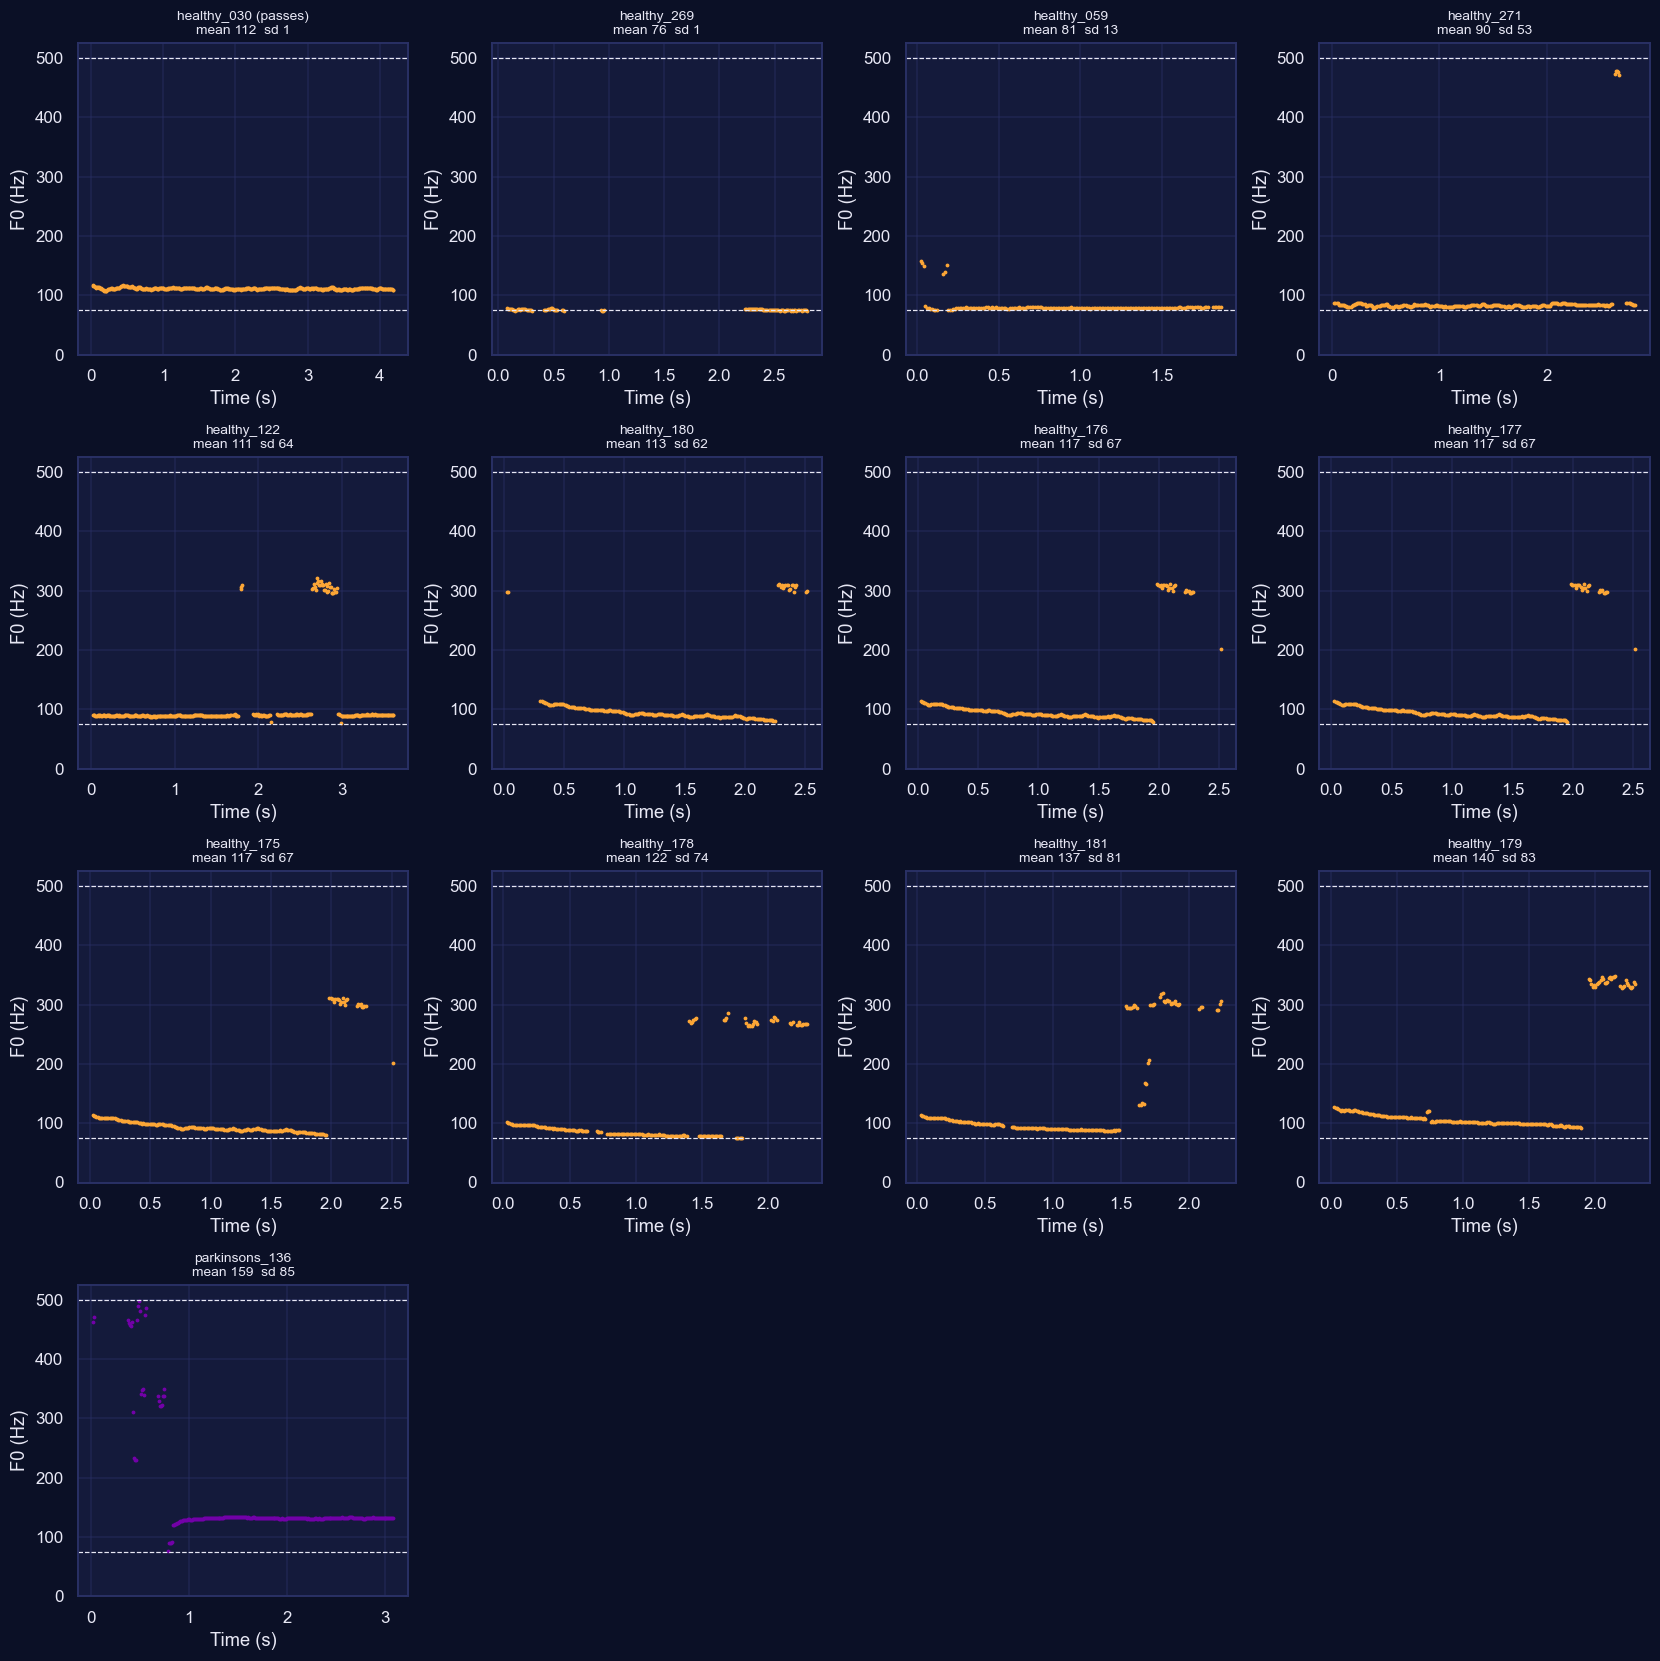

In [13]:
# Pitch contours of the recordings that fail the F0 rule, next to one passing example
fail = data[~data["qc_f0"]].sort_values("f0_mean")
good = data[data["qc_f0"] & (data.label == "Healthy")].sample(1, random_state=SEED)
show = pd.concat([good, fail])
path_of = insp.set_index("recording_id")["path"]

fig, axes = make_grid(len(show), ncols=4, size=3.8)
for k, (ax, r) in enumerate(zip(axes, show.itertuples())):
    y = load_clean(path_of[r.recording_id])
    snd = parselmouth.Sound(y.astype(np.float64), sampling_frequency=float(SR))
    pitch = snd.to_pitch(time_step=0.01, pitch_floor=F0_MIN, pitch_ceiling=F0_MAX)
    f0 = pitch.selected_array["frequency"]
    ax.plot(pitch.xs(), np.where(f0 > 0, f0, np.nan), ".", ms=3, color=LABEL_COLORS[r.label])
    ax.axhline(F0_MIN, color=TEXT, ls="--", lw=0.8)
    ax.axhline(F0_MAX, color=TEXT, ls="--", lw=0.8)
    ax.set_ylim(0, F0_MAX * 1.05)
    tag = " (passes)" if k == 0 else ""
    ax.set_title(f"{r.recording_id}{tag}\nmean {r.f0_mean:.0f}  sd {r.f0_std:.0f}", fontsize=9)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("F0 (Hz)")
plt.tight_layout()
plt.show()

In [14]:
# target selection and modelling dataframe
GROUP_COLS = OrderedDict([
    ("f0", ["f0_mean"]),
    ("jitter", ["jitter"]),
    ("shimmer", ["shimmer"]),
    ("hnr", ["hnr"]),
    ("mfcc", [f"mfcc_{i}" for i in range(1, 14)]),
    ("spectral", ["spec_centroid", "spec_bandwidth", "spec_entropy"]),
])
GROUP_QC = dict(f0="qc_f0", jitter="qc_jitter", shimmer="qc_shimmer", hnr="qc_hnr", mfcc="qc_spec", spectral="qc_spec")

USE_GROUPS = ["f0", "jitter", "shimmer", "hnr", "mfcc", "spectral"]

TARGET_COLS = [c for g in USE_GROUPS for c in GROUP_COLS[g]]
GROUP_SLICES = OrderedDict()
a = 0
for g in USE_GROUPS:
    GROUP_SLICES[g] = (a, a + len(GROUP_COLS[g]))
    a += len(GROUP_COLS[g])

keep = data["qc_dur"].copy()
for g in USE_GROUPS:
    keep &= data[GROUP_QC[g]]
md = data[keep].copy()
md["row"] = md.index.values
md = md.reset_index(drop=True)

print("Targets:", TARGET_COLS)
print("Retained for modelling:", len(md), "of", len(data))
print(pd.DataFrame({"total": data.groupby("label").size(), "retained": md.groupby("label").size()})
      .assign(retained_frac=lambda d: (d.retained / d.total).round(3)))
print("Large differences in retained fraction between labels indicate selection bias and should be reported.")

Targets: ['f0_mean', 'jitter', 'shimmer', 'hnr', 'mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 'mfcc_11', 'mfcc_12', 'mfcc_13', 'spec_centroid', 'spec_bandwidth', 'spec_entropy']
Retained for modelling: 554 of 566
            total  retained  retained_frac
label                                     
Healthy       287       276          0.962
Parkinsons    279       278          0.996
Large differences in retained fraction between labels indicate selection bias and should be reported.


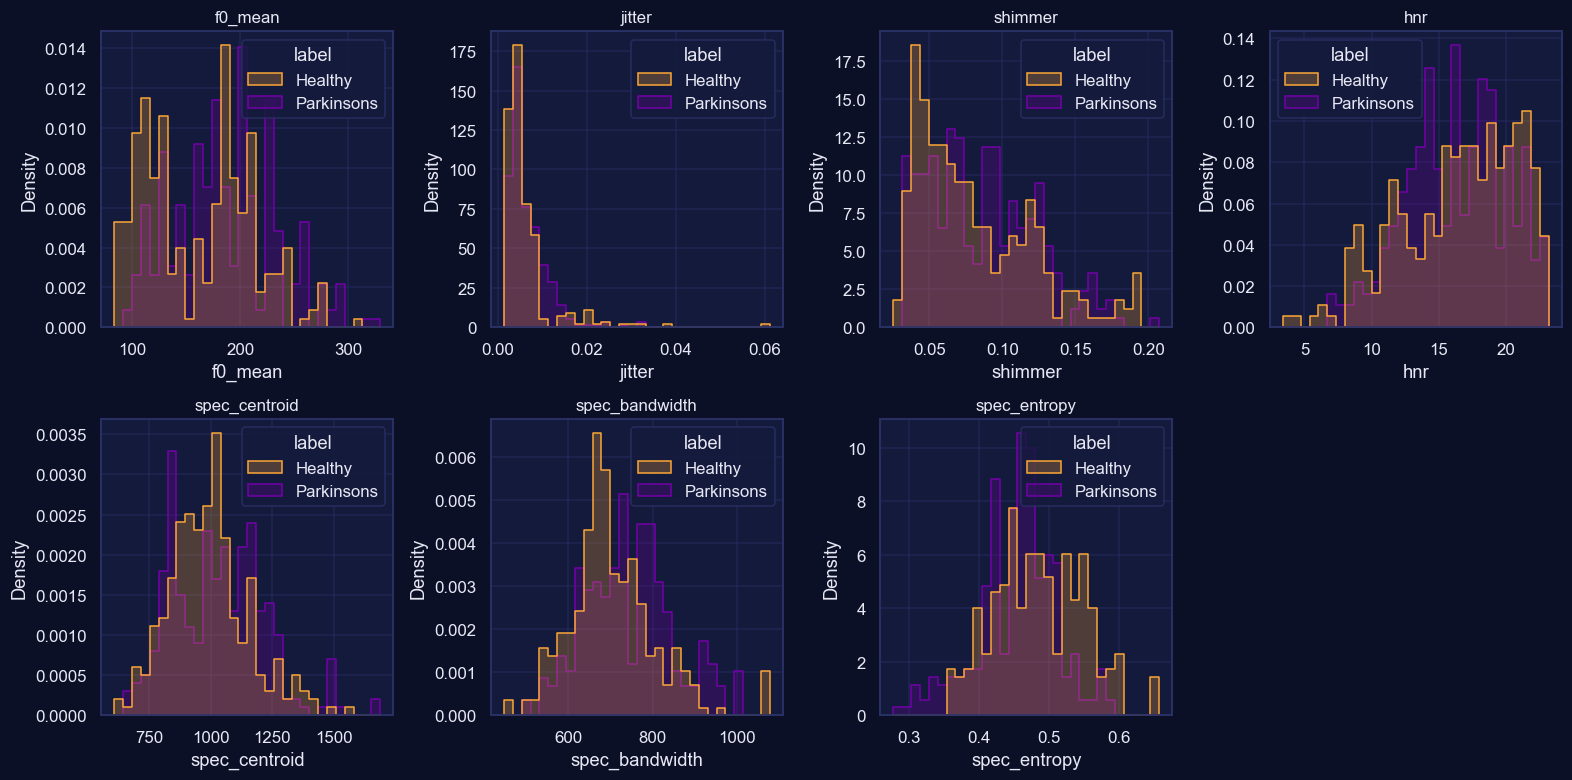

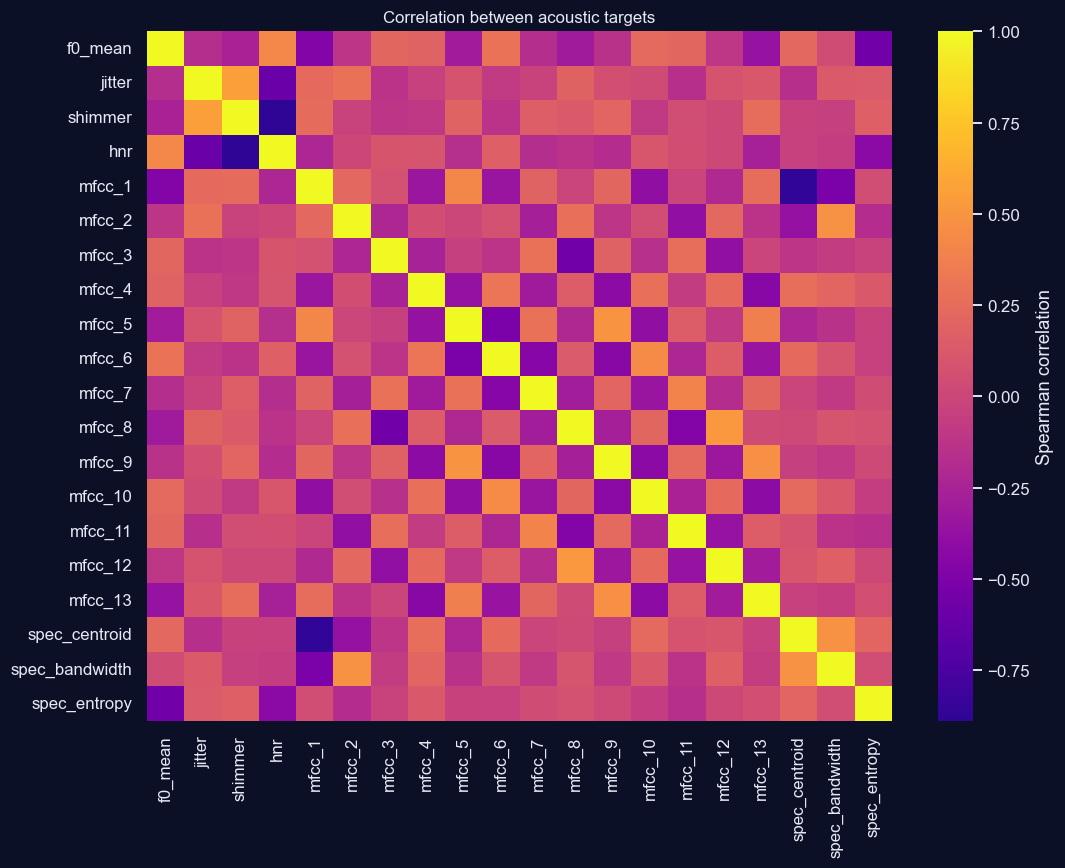

Descriptive group comparison (file level; files may not be independent, so treat p-values with caution):


,target,healthy_median,parkinsons_median,mannwhitney_p
0,f0_mean,164.38964,182.60330,0.00000
1,jitter,0.00459,0.00529,0.00602
2,shimmer,0.07043,0.08509,0.03357
3,hnr,17.14191,16.33740,0.20445
4,spec_centroid,984.32319,1029.94903,0.03112
5,spec_bandwidth,689.58876,735.47028,0.00000
6,spec_entropy,0.48242,0.46252,0.00000


In [15]:
# Exploratory data analysis
core = [c for c in TARGET_COLS if not c.startswith("mfcc_")]
fig, axes = make_grid(len(core), ncols=4, size=3.6)
for ax, c in zip(axes, core):
    sns.histplot(data=md, x=c, hue="label", palette=LABEL_COLORS, element="step", stat="density",
                 common_norm=False, bins=30, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(md[TARGET_COLS].corr(method="spearman"), cmap="plasma", center=0, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Correlation between acoustic targets")
ax.grid(False)
plt.tight_layout()
plt.show()

rows = []
for c in core:
    a_ = md.loc[md.label == "Healthy", c]
    b_ = md.loc[md.label == "Parkinsons", c]
    rows.append(dict(target=c, healthy_median=a_.median(), parkinsons_median=b_.median(),
                     mannwhitney_p=stats.mannwhitneyu(a_, b_).pvalue))
print("Descriptive group comparison (file level; files may not be independent, so treat p-values with caution):")
display(pd.DataFrame(rows).round(5))

In [16]:
# proxy speaker groups and leakage-aware 70/15/15 split
FP_COLS = [f"mfcc_{i}" for i in range(1, 14)] + [f"fp_mfcc_std_{i}" for i in range(1, 14)]
GROUP_QUANTILE = 0.05   # higher values merge more recordings into one group (stricter, fewer groups)

# Checking whether consecutive filenames look acoustically similar 
rng = np.random.default_rng(SEED)
for lab in ["Healthy", "Parkinsons"]:
    sub = md[md.label == lab].sort_values("index")
    Z = StandardScaler().fit_transform(sub[FP_COLS].values)
    adj = np.linalg.norm(Z[1:] - Z[:-1], axis=1).mean()
    perm = rng.permutation(len(Z))
    rnd = np.linalg.norm(Z[perm][1:] - Z[perm][:-1], axis=1).mean()
    print(f"{lab}: consecutive-file distance {adj:.3f} | random-pair distance {rnd:.3f} | ratio {adj / rnd:.3f}")

# Clustering within each label so that a group never mixes Healthy and Parkinsons files
md["group"] = -1
next_gid = 0
for lab in md["label"].unique():
    sub = md[md.label == lab]
    Z = StandardScaler().fit_transform(sub[FP_COLS].values)
    thr = np.quantile(pdist(Z), GROUP_QUANTILE)
    cl = AgglomerativeClustering(n_clusters=None, distance_threshold=thr, linkage="average").fit_predict(Z)
    md.loc[sub.index, "group"] = cl + next_gid
    next_gid += int(cl.max()) + 1

sizes = md.groupby("group").size()
print("\nProxy groups:", sizes.shape[0], "| median size:", sizes.median(), "| largest group:", sizes.max(),
      f"({sizes.max() / len(md):.1%} of recordings)")
if sizes.max() / len(md) > 0.20:
    print("Warning: one group is very large. Lower GROUP_QUANTILE for a less aggressive grouping.")

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
md["fold"] = -1
for k, (_, te_idx) in enumerate(sgkf.split(md, md["label"], groups=md["group"])):
    md.loc[md.index[te_idx], "fold"] = k
md["split"] = np.where(md.fold == 0, "test", np.where(md.fold == 1, "val", "train"))

g_tr = set(md.loc[md.split == "train", "group"])
g_va = set(md.loc[md.split == "val", "group"])
g_te = set(md.loc[md.split == "test", "group"])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "Group leakage between splits"

print("\nSplit sizes and label balance:")
print(pd.crosstab(md["split"], md["label"], margins=True))
print("\nLimitation: groups are acoustic proxies, not verified speaker identities, so residual speaker overlap is possible.")

Healthy: consecutive-file distance 4.615 | random-pair distance 6.932 | ratio 0.666
Parkinsons: consecutive-file distance 4.428 | random-pair distance 6.785 | ratio 0.653

Proxy groups: 148 | median size: 2.0 | largest group: 35 (6.3% of recordings)

Split sizes and label balance:
label  Healthy  Parkinsons  All
split                          
test        31          36   67
train      218         189  407
val         27          53   80
All        276         278  554

Limitation: groups are acoustic proxies, not verified speaker identities, so residual speaker overlap is possible.


In [17]:
# Starget transformation, scaling (training statistics only) and metric functions
idx_tr = np.where(md.split == "train")[0]
idx_va = np.where(md.split == "val")[0]
idx_te = np.where(md.split == "test")[0]

Y_raw = md[TARGET_COLS].values.astype(np.float64)
LOG_COLS = [c for c in ["jitter", "shimmer"] if c in TARGET_COLS]
log_idx = [TARGET_COLS.index(c) for c in LOG_COLS]

def fwd(Y):
    Z = Y.copy()
    if log_idx:
        Z[:, log_idx] = np.log(Z[:, log_idx])
    return Z

Z_all = fwd(Y_raw)
Y_mu = Z_all[idx_tr].mean(axis=0)
Y_sd = Z_all[idx_tr].std(axis=0) + 1e-9
Y_std = (Z_all - Y_mu) / Y_sd
SD_TRAIN_ORIG = Y_raw[idx_tr].std(axis=0)

def inv_cols(P, cols):
    P = np.clip(P, -10, 10)
    Z = P * Y_sd[cols] + Y_mu[cols]
    for j, c in enumerate(cols):
        if c in log_idx:
            Z[:, j] = np.exp(Z[:, j])
    return Z

ALL_COLS = list(range(len(TARGET_COLS)))
Y_SPLIT = {"val": Y_raw[idx_va], "test": Y_raw[idx_te]}

def ccc_score(y, p):
    my, mp = y.mean(), p.mean()
    cov = np.mean((y - my) * (p - mp))
    return 2 * cov / (y.var() + p.var() + (my - mp) ** 2 + 1e-12)

def reg_metrics(y, p):
    ss_res = np.sum((y - p) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    ok = np.std(y) > 0 and np.std(p) > 0
    return dict(MAE=float(np.mean(np.abs(y - p))), RMSE=float(np.sqrt(np.mean((y - p) ** 2))),
                R2=float(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan,
                Pearson=float(stats.pearsonr(y, p)[0]) if ok else np.nan,
                Spearman=float(stats.spearmanr(y, p)[0]) if ok else np.nan,
                CCC=float(ccc_score(y, p)))

def eval_pred(Y, P, names=None):
    names = names or TARGET_COLS
    rows = []
    for j, c in enumerate(names):
        d = reg_metrics(Y[:, j], P[:, j])
        d["target"] = c
        rows.append(d)
    return pd.DataFrame(rows)[["target", "MAE", "RMSE", "R2", "Pearson", "Spearman", "CCC"]]

def agg_nrmse(Y, P, cols=None):
    sd = SD_TRAIN_ORIG if cols is None else SD_TRAIN_ORIG[cols]
    return float(np.mean(np.sqrt(np.mean((Y - P) ** 2, axis=0)) / sd))

print("Train/val/test sizes:", len(idx_tr), len(idx_va), len(idx_te))

Train/val/test sizes: 407 80 67


In [18]:
# conventional machine learning baselines (same features and same split for all)
FT_COLS = [c for c in md.columns if c.startswith("ft_")]
X_ft = md[FT_COLS].values
ft_scaler = StandardScaler().fit(X_ft[idx_tr])
X_ft_s = ft_scaler.transform(X_ft)

base_models = OrderedDict([
    ("RandomForest", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
    ("XGBoost", MultiOutputRegressor(XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                                  colsample_bytree=0.8, random_state=SEED, n_jobs=-1))),
    ("SVR", MultiOutputRegressor(SVR(C=3.0, epsilon=0.05, gamma="scale"))),
    ("CatBoost", CatBoostRegressor(loss_function="MultiRMSE", iterations=600, depth=6, learning_rate=0.05,
                                   random_seed=SEED, verbose=0)),
])

PREDS = OrderedDict()
BASE_FIT, BASE_TIME = {}, {}
for name, mdl in base_models.items():
    t0 = time.time()
    mdl.fit(X_ft_s[idx_tr], Y_std[idx_tr])
    BASE_TIME[name] = time.time() - t0
    BASE_FIT[name] = mdl
    PREDS[name] = [dict(val=inv_cols(mdl.predict(X_ft_s[idx_va]), ALL_COLS),
                        test=inv_cols(mdl.predict(X_ft_s[idx_te]), ALL_COLS))]
    print(f"{name}: fitted in {BASE_TIME[name]:.1f} s | val nRMSE {agg_nrmse(Y_SPLIT['val'], PREDS[name][0]['val']):.3f}")

RandomForest: fitted in 9.4 s | val nRMSE 0.837
XGBoost: fitted in 123.9 s | val nRMSE 0.686
SVR: fitted in 0.8 s | val nRMSE 0.593
CatBoost: fitted in 447.1 s | val nRMSE 0.726


In [19]:
# tensors for deep learning (normalization statistics from training recordings only)
rows_md = md["row"].values
NFR_MD = NFR_ALL[rows_md]
valid_fr = np.arange(T_FIXED)[None, :] < NFR_MD[:, None]

def fit_frame_stats(A):
    m = valid_fr[idx_tr][:, None, :]
    X = A[idx_tr]
    cnt = m.sum()
    mu = (X * m).sum(axis=(0, 2)) / cnt
    var = (((X - mu[None, :, None]) ** 2) * m).sum(axis=(0, 2)) / cnt
    return mu.astype(np.float32), (np.sqrt(var) + 1e-6).astype(np.float32)

def norm2d(A, mu, sd):
    return ((A - mu[None, :, None]) / sd[None, :, None]) * valid_fr[:, None, :]

MEL_RAW = MEL_ALL[rows_md]
MFCC_RAW = MFCC_ALL[rows_md]
WAVE_RAW = WAVE_ALL[rows_md]
MEL_MU, MEL_SD = fit_frame_stats(MEL_RAW)
MFCC_MU, MFCC_SD = fit_frame_stats(MFCC_RAW)

nsamp = md["n_samples"].values
valid_w = np.arange(L_FIXED)[None, :] < nsamp[:, None]
WAVE_SD = float(np.sqrt(((WAVE_RAW[idx_tr] ** 2) * valid_w[idx_tr]).sum() / valid_w[idx_tr].sum()))

TENSORS = {
    "mel": torch.tensor(norm2d(MEL_RAW, MEL_MU, MEL_SD), dtype=torch.float32).unsqueeze(1),
    "mfcc": torch.tensor(norm2d(MFCC_RAW, MFCC_MU, MFCC_SD), dtype=torch.float32).unsqueeze(1),
    "wave": torch.tensor(WAVE_RAW / WAVE_SD, dtype=torch.float32).unsqueeze(1),
}
FRAC_T = torch.tensor(NFR_MD / T_FIXED, dtype=torch.float32)
Y_T = torch.tensor(Y_std, dtype=torch.float32)
for k, v in TENSORS.items():
    print(k, tuple(v.shape))

mel (554, 1, 64, 501)
mfcc (554, 1, 20, 501)
wave (554, 1, 40000)


In [20]:
# Model architectures
def make_mask(frac, Tp):
    valid = torch.ceil(frac * Tp).clamp(min=1, max=Tp).long()
    mask = torch.arange(Tp, device=frac.device)[None, :] < valid[:, None]
    return mask, valid

def masked_mean(h, mask):
    m = mask.unsqueeze(-1).float()
    return (h * m).sum(1) / m.sum(1).clamp(min=1)

class Enc2D(nn.Module):
    def __init__(self, n_freq, n_time, base=16, out_dim=128, drop=0.2):
        super().__init__()
        chs = [base, base * 2, base * 4]
        pools = [(2, 2), (2, 2), (2, 1)]
        layers, prev = [], 1
        for c, p in zip(chs, pools):
            layers += [nn.Conv2d(prev, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(),
                       nn.MaxPool2d(p), nn.Dropout2d(drop * 0.5)]
            prev = c
        self.cnn = nn.Sequential(*layers)
        self.cnn.eval()
        with torch.no_grad():
            z = self.cnn(torch.zeros(1, 1, n_freq, n_time))
        self.cnn.train()
        self.proj = nn.Sequential(nn.Linear(z.shape[1] * z.shape[2], out_dim), nn.ReLU(), nn.Dropout(drop))

    def forward(self, x):
        z = self.cnn(x)
        B, C, Fp, Tp = z.shape
        return self.proj(z.permute(0, 3, 1, 2).reshape(B, Tp, C * Fp))

class Enc1D(nn.Module):
    def __init__(self, hop, base=16, out_dim=128, drop=0.2):
        super().__init__()
        k = int(2.5 * hop)
        c1 = base * 2
        self.cnn = nn.Sequential(
            nn.Conv1d(1, c1, kernel_size=k, stride=hop, padding=k // 2), nn.BatchNorm1d(c1), nn.ReLU(),
            nn.Conv1d(c1, c1 * 2, 5, padding=2), nn.BatchNorm1d(c1 * 2), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(drop * 0.5),
            nn.Conv1d(c1 * 2, c1 * 4, 5, padding=2), nn.BatchNorm1d(c1 * 4), nn.ReLU(), nn.MaxPool1d(2))
        self.proj = nn.Sequential(nn.Linear(c1 * 4, out_dim), nn.ReLU(), nn.Dropout(drop))

    def forward(self, x):
        z = self.cnn(x).transpose(1, 2)
        return self.proj(z)

class SinusoidalPE(nn.Module):
    def __init__(self, d, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-np.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.shape[1]]

class AcousticNet(nn.Module):
    # arch: cnn, bilstm, attn, transformer. multi_head=True gives one regression head per target group.
    def __init__(self, rep, arch, group_dims, shape, multi_head=False, base=16, d=128, hidden=64, drop=0.2):
        super().__init__()
        self.arch = arch
        self.multi_head = multi_head
        self.group_dims = OrderedDict(group_dims)
        self.enc = Enc1D(HOP, base, d, drop) if rep == "wave" else Enc2D(shape[0], shape[1], base, d, drop)
        feat = d
        if arch == "bilstm":
            self.rnn = nn.LSTM(d, hidden, batch_first=True, bidirectional=True)
            feat = 2 * hidden
        elif arch == "attn":
            self.att = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 1))
        elif arch == "transformer":
            self.pos = SinusoidalPE(d)
            layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=2 * d, dropout=drop, batch_first=True)
            self.tr = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.shared = nn.Sequential(nn.Linear(feat, 64), nn.ReLU(), nn.Dropout(drop))
        if multi_head:
            self.heads = nn.ModuleDict({g: nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, dm))
                                        for g, dm in self.group_dims.items()})
        else:
            self.out = nn.Linear(64, sum(self.group_dims.values()))

    def forward(self, x, frac):
        h = self.enc(x)
        mask, valid = make_mask(frac, h.shape[1])
        if self.arch == "cnn":
            z = masked_mean(h, mask)
        elif self.arch == "bilstm":
            packed = nn.utils.rnn.pack_padded_sequence(h, valid.cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.rnn(packed)
            o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=h.shape[1])
            z = masked_mean(o, mask)
        elif self.arch == "attn":
            s = self.att(h).squeeze(-1).masked_fill(~mask, -1e9)
            w = torch.softmax(s, dim=1).unsqueeze(-1)
            z = (h * w).sum(1)
        else:
            z = masked_mean(self.tr(self.pos(h), src_key_padding_mask=~mask), mask)
        z = self.shared(z)
        if self.multi_head:
            return torch.cat([self.heads[g](z) for g in self.group_dims], dim=1)
        return self.out(z)

# Quick shape check
_args = dict(rep="mel", arch="bilstm", group_dims=OrderedDict((g, len(GROUP_COLS[g])) for g in USE_GROUPS),
             shape=tuple(TENSORS["mel"].shape[2:]), multi_head=True)
_m = AcousticNet(**_args).eval()
print("Output shape:", _m(TENSORS["mel"][:2], FRAC_T[:2]).shape, "| parameters:", sum(p.numel() for p in _m.parameters()))
del _m

Output shape: torch.Size([2, 20]) | parameters: 209908


In [21]:
# training utilities (AdamW, LR scheduling, dropout, weight decay, early stopping)
SEEDS = [11, 22, 33]      
EPOCHS = 80
BATCH = 32
PARAMS = dict(base=16, d=128, hidden=64, drop=0.2, lr=1e-3, wd=1e-4)
RUNS = {}

def mt_loss(pred, y, slices, weights=None):
    # Weighted multi-task MSE: L_total = sum_i w_i * L_i, one task per target group, equal weights by default
    tot = 0.0
    for g, (a, b) in slices.items():
        w = 1.0 if weights is None else weights[g]
        tot = tot + w * F.mse_loss(pred[:, a:b], y[:, a:b])
    return tot

def make_loader(rep, idx, shuffle, cols):
    ds = TensorDataset(TENSORS[rep][idx], FRAC_T[idx], Y_T[idx][:, cols])
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=shuffle)

def predict_std(model, x, frac, bs=64):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), bs):
            out.append(model(x[i:i + bs].to(DEVICE), frac[i:i + bs].to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def run_one(arch, rep, seed, groups=None, multi_head=False, params=None, epochs=None, cache=True, patience=12):
    groups = list(groups) if groups else list(USE_GROUPS)
    params = dict(PARAMS if params is None else params)
    epochs = epochs or EPOCHS
    key = f"{arch}|{rep}|{'+'.join(groups)}|{int(multi_head)}|{seed}"
    if cache and key in RUNS:
        return RUNS[key]

    group_dims = OrderedDict((g, len(GROUP_COLS[g])) for g in groups)
    cols = [TARGET_COLS.index(c) for g in groups for c in GROUP_COLS[g]]
    slices, a = OrderedDict(), 0
    for g, dm in group_dims.items():
        slices[g] = (a, a + dm)
        a += dm

    set_seed(seed)
    shape = tuple(TENSORS[rep].shape[2:]) if rep != "wave" else None
    build_args = dict(rep=rep, arch=arch, group_dims=dict(group_dims), shape=shape, multi_head=multi_head,
                      base=params["base"], d=params["d"], hidden=params["hidden"], drop=params["drop"])
    model = AcousticNet(**build_args).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["wd"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    tl = make_loader(rep, idx_tr, True, cols)
    vl = make_loader(rep, idx_va, False, cols)

    best, best_state, bad = np.inf, None, 0
    hist = dict(train=[], val=[])
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot, n = 0.0, 0
        for xb, fb, yb in tl:
            xb, fb, yb = xb.to(DEVICE), fb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = mt_loss(model(xb, fb), yb, slices)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        model.eval()
        vt, vn = 0.0, 0
        with torch.no_grad():
            for xb, fb, yb in vl:
                xb, fb, yb = xb.to(DEVICE), fb.to(DEVICE), yb.to(DEVICE)
                vt += mt_loss(model(xb, fb), yb, slices).item() * len(xb)
                vn += len(xb)
        tr_l, va_l = tot / n, vt / vn
        hist["train"].append(tr_l)
        hist["val"].append(va_l)
        sched.step(va_l)
        if va_l < best - 1e-4:
            best, bad = va_l, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    train_time = time.time() - t0
    if best_state is not None:
        model.load_state_dict(best_state)

    pv = inv_cols(predict_std(model, TENSORS[rep][idx_va], FRAC_T[idx_va]), cols)
    pt = inv_cols(predict_std(model, TENSORS[rep][idx_te], FRAC_T[idx_te]), cols)
    ckpt = None
    if cache:
        ckpt = os.path.join(CKPT_DIR, key.replace("|", "_").replace("+", "-") + ".pt")
        torch.save(dict(state=best_state, build_args=build_args, cols=cols, params=params, seed=seed), ckpt)
    run = dict(key=key, cols=cols, pred=dict(val=pv, test=pt), hist=hist,
               n_params=int(sum(p.numel() for p in model.parameters())), train_time=train_time,
               ckpt=ckpt, build_args=build_args, epochs_run=len(hist["train"]),
               gpu_mb=(torch.cuda.max_memory_allocated() / 1e6) if DEVICE.type == "cuda" else None,
               rss_mb=(psutil.Process().memory_info().rss / 1e6) if psutil else None)
    if cache:
        RUNS[key] = run
    return run

In [23]:
# hyperparameter tuning of the main model with Optuna (validation set only)
N_TRIALS = 12
TUNE_EPOCHS = 30

def objective(trial):
    params = dict(base=trial.suggest_categorical("base", [8, 16, 24]),
                  d=trial.suggest_categorical("d", [64, 128, 192]),
                  hidden=trial.suggest_categorical("hidden", [32, 64, 96]),
                  drop=trial.suggest_float("drop", 0.1, 0.5),
                  lr=trial.suggest_float("lr", 3e-4, 3e-3, log=True),
                  wd=trial.suggest_float("wd", 1e-6, 1e-2, log=True))
    run = run_one("bilstm", "mel", SEED, multi_head=True, params=params, epochs=TUNE_EPOCHS, cache=False, patience=8)
    return agg_nrmse(Y_SPLIT["val"], run["pred"]["val"])

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
print("Best validation nRMSE:", round(study.best_value, 4))
print("Best parameters:", study.best_params)

PARAMS = dict(study.best_params)   # these parameters are used for all deep models below
with open(os.path.join(OUT_DIR, "best_params.json"), "w") as f:
    json.dump(PARAMS, f, indent=2)

  0%|          | 0/12 [00:00<?, ?it/s]

Best validation nRMSE: 0.7518
Best parameters: {'base': 24, 'd': 128, 'hidden': 64, 'drop': 0.21149915374204675, 'lr': 0.0020813602050155505, 'wd': 0.0037514447467611087}


In [ ]:
MODEL_SPECS = OrderedDict([
    ("CNN", dict(arch="cnn", rep="mel", mh=False, single=False)),
    ("CNN-BiLSTM", dict(arch="bilstm", rep="mel", mh=False, single=False)),
    ("CNN-Attention", dict(arch="attn", rep="mel", mh=False, single=False)),
    ("CNN-Transformer", dict(arch="transformer", rep="mel", mh=False, single=False)),
    ("MT-CNN-BiLSTM", dict(arch="bilstm", rep="mel", mh=True, single=False)),
    ("MT-CNN-BiLSTM [wave]", dict(arch="bilstm", rep="wave", mh=True, single=False)),
    ("MT-CNN-BiLSTM [mfcc]", dict(arch="bilstm", rep="mfcc", mh=True, single=False)),
    ("ST-CNN", dict(arch="cnn", rep="mel", mh=False, single=True)),
    ("ST-CNN-BiLSTM", dict(arch="bilstm", rep="mel", mh=False, single=True)),
])

def get_pred(name, seed):
    spec = MODEL_SPECS[name]
    if not spec["single"]:
        r = run_one(spec["arch"], spec["rep"], seed, multi_head=spec["mh"])
        return dict(val=r["pred"]["val"], test=r["pred"]["test"])
    out = {s: np.zeros((len(Y_SPLIT[s]), len(TARGET_COLS))) for s in ["val", "test"]}
    for g in USE_GROUPS:
        r = run_one(spec["arch"], spec["rep"], seed, groups=[g], multi_head=False)
        for s in out:
            out[s][:, r["cols"]] = r["pred"][s]
    return out

for name in MODEL_SPECS:
    PREDS[name] = [get_pred(name, s) for s in tqdm(SEEDS, desc=name)]
print("Finished. Models available:", list(PREDS.keys()))

CNN:   0%|          | 0/3 [00:02<?, ?it/s]

CNN-BiLSTM:   0%|          | 0/3 [00:00<?, ?it/s]